# Scratch100k taxv2: evaluation at 512 px

Follow-up to `Scratch100k_TaxV2_Weights.ipynb`. The same checkpoints (base and the four w=0.5 runs: distance, KL, partial
CE, KL w=0.5 + partial CE w=0.1; 25k / 50k / 75k / 100k) are re-evaluated at **512 px** instead of 256 px. Training is
unchanged: 256 px, 75k updates at constant LR then a 25k cooldown, dedup CoralNet splits, data seed 4, pinned concept CSV.
Only the prediction resolution differs (`sbatch slurm/scratch100k_eval.sbatch CKPT OUT CONCEPTS CSV 512`, which uses
`configs/model_config_cbm_dpt_lora_vitl.yaml`); the w=0.1 runs were not re-evaluated.

Two questions:
1. How much does evaluating at 512 px change each run (512 − 256 on the same checkpoint)?
2. Do the differences vs base found at 256 px still hold at 512 px?

Colours as before: hue = loss, KL + partial CE in purple. Where both resolutions are shown, 512 px is solid and 256 px is
lighter and dashed. One seed per configuration.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

REPO = Path("..").resolve() if Path("../eval_out").exists() else Path(".").resolve()
ROOT = REPO / "eval_out/scratch100k_hier"
CKPTS = REPO / "nbs/model_checkpoints"
PREFIX = "cbm_scratch100k_"
TAG = "taxv2"
RES, LOW = 512, 256
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus"]
PAIRS = [f"{c}->{f}" for c, f in zip(RANKS, RANKS[1:])]
EVALS = {"coralnet": "CoralNet val (dedup)", "pacific": "Pacific val"}
COOLDOWN = (75000, 100000)  # linear LR cooldown to 0
REF = f"base_{TAG}"

LOSSES = {
    "base": ("base", "#2a78d6", "o"),
    "distance": ("distance", "#eb6834", "s"),
    "kl": ("KL", "#1baf7a", "^"),
    "partial": ("partial CE", "#eda100", "D"),
    "klpartial": ("KL + partial CE", "#8a4fd0", "P"),
}
INK, MUTED, GRID, BAND, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#ebeae6", "#fcfcfb"


def shade(color, mix):
    rgb = [int(color[i:i + 2], 16) for i in (1, 3, 5)]
    target = 255 if mix > 0 else 0
    return "#" + "".join(f"{round(c + (target - c) * abs(mix)):02x}" for c in rgb)


def parse(run):
    """'kl_w0.5_taxv2' -> ('kl', '0.5'); 'klpartial_w0.5_0.1_taxv2' -> ('klpartial', '0.5_0.1')."""
    loss, _, weight = run.removesuffix("_" + TAG).partition("_w")
    return loss, weight


def style(run, res=RES):
    """(label, colour, marker, linestyle) of a short run name; 256 px is lighter and dashed."""
    loss, weight = parse(run)
    name, color, marker = LOSSES[loss]
    label = f"{name} w={weight.replace('_', '/')}" if weight else name
    if res != RES:
        return f"{label} @{res}", shade(color, 0.45), marker, "--"
    return label, color, marker, "-"


def order(run):
    loss, weight = parse(run)
    return list(LOSSES).index(loss), float(weight.split("_")[0] or 0)


plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 200)

ALL = pd.read_csv(ROOT / "compiled.csv")
ALL["run"] = ALL.run.str.removeprefix(PREFIX)
RUNS = sorted((r for r in ALL[ALL.resolution == RES].run.unique() if r.endswith("_" + TAG)), key=order)
ALL = ALL[ALL.run.isin(RUNS) & ALL.resolution.isin([RES, LOW])].sort_values(["run", "resolution", "step"])
ALL = ALL.set_index(["run", "resolution", "step"])
df = ALL.xs(RES, level="resolution")      # 512 px
lo = ALL.xs(LOW, level="resolution")      # same checkpoints at 256 px
EVALUATED = {r: sorted(df.loc[r].index) for r in RUNS}
STEPS = sorted({s for r in RUNS for s in EVALUATED[r]})
COMPARE = [r for r in RUNS if r != REF]


def plot_run(ax, run, x, y, res=RES, **kw):
    label, color, marker, ls = style(run, res)
    ax.plot(x, y, color=color, marker=marker, ls=ls, lw=2 if res == RES else 1.4, ms=6 if res == RES else 4.5,
            mec="white", mew=0.8, label=label, **kw)


def step_axis(ax, steps):
    ax.set_xticks(steps)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v / 1000)}k"))
    if steps[-1] > COOLDOWN[0]:
        ax.axvspan(*COOLDOWN, color=BAND, lw=0, zorder=0)


def run_legend(fig, runs, y=1.0, ncol=None, res=RES):
    handles = [Line2D([], [], color=style(r, res)[1], marker=style(r, res)[2], ls=style(r, res)[3], lw=2,
                      label=style(r, res)[0].removesuffix(f" @{res}")) for r in runs]
    fig.legend(handles=handles, loc="upper right", ncol=ncol or len(handles), bbox_to_anchor=(1, y), fontsize=9)


def delta(run, col, ref=REF, table=None):
    """run − ref at the steps both have (raw units), as a Series indexed by step."""
    table = df if table is None else table
    a, b = table.loc[run, col], table.loc[ref, col]
    common = [s for s in a.index if s in b.index]
    return a.loc[common] - b.loc[common]


print("runs:", RUNS)
print("steps evaluated at 512:", STEPS)

runs: ['base_taxv2', 'distance_w0.5_taxv2', 'kl_w0.5_taxv2', 'partial_w0.5_taxv2', 'klpartial_w0.5_0.1_taxv2']
steps evaluated at 512: [25000, 50000, 75000, 100000]


## 0. What has been evaluated
Finished evals (rows of `compiled.csv`) at each resolution, and the checksum of each run's pinned concept CSV: all should
match.

In [2]:
def csv_sha(run):
    p = CKPTS / f"{PREFIX}{run}/class_to_concepts.csv"
    return hashlib.sha1(p.read_bytes()).hexdigest()[:12] if p.exists() else "—"


status = pd.DataFrame(
    [[" / ".join(f"{res}" for res in (LOW, RES) if (r, res, s) in ALL.index) or "—"
      for s in (25000, 50000, 75000, 100000)] + [csv_sha(r)] for r in RUNS],
    index=[style(r)[0] for r in RUNS], columns=["25k", "50k", "75k", "100k (cooldown)", "pinned CSV sha1"])
status

,25k,50k,75k,100k (cooldown),pinned CSV sha1
base,256 / 512,256 / 512,256 / 512,256 / 512,d46f6fe76c31
distance w=0.5,256 / 512,256 / 512,256 / 512,256 / 512,d46f6fe76c31
KL w=0.5,256 / 512,256 / 512,256 / 512,256 / 512,d46f6fe76c31
partial CE w=0.5,256 / 512,256 / 512,256 / 512,256 / 512,d46f6fe76c31
KL + partial CE w=0.5/0.1,256 / 512,256 / 512,256 / 512,256 / 512,d46f6fe76c31


## 1. Headline metrics at 512 px
All five runs at 512 px (solid), with the same checkpoints at 256 px for reference (lighter, dashed). Grey = LR cooldown.

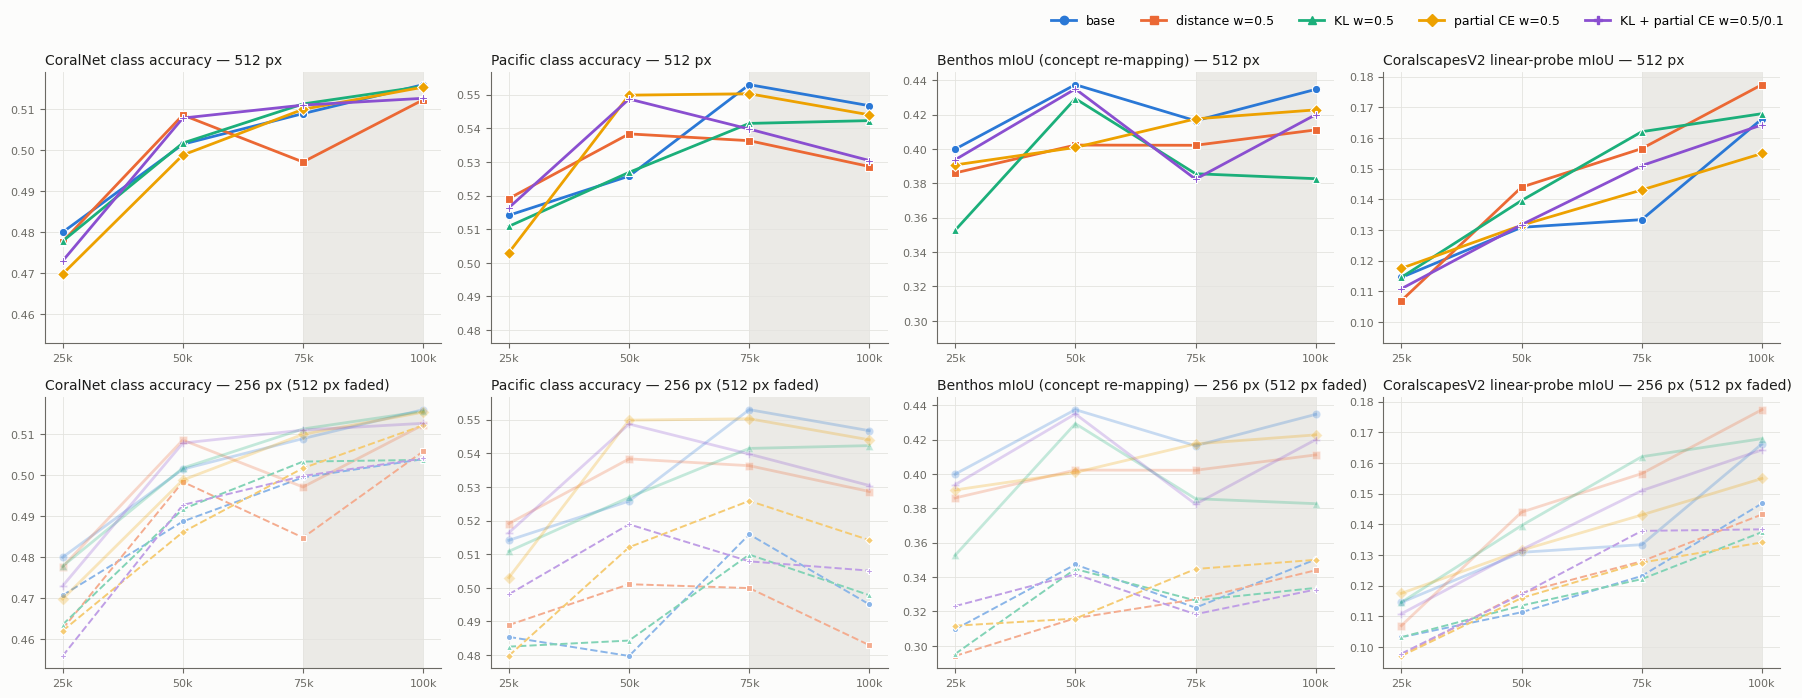

In [3]:
HEADLINE = [
    ("coralnet/class_accuracy", "CoralNet class accuracy"),
    ("pacific/class_accuracy", "Pacific class accuracy"),
    ("benthos/miou", "Benthos mIoU (concept re-mapping)"),
    ("coralscapes/miou", "CoralscapesV2 linear-probe mIoU"),
]
fig, axes = plt.subplots(2, len(HEADLINE), figsize=(18, 7), sharey="col")
for row, show_low in zip(axes, (False, True)):
    for ax, (col, name) in zip(row, HEADLINE):
        for run in RUNS:
            if show_low:
                plot_run(ax, run, lo.loc[run, col].index, lo.loc[run, col].values, res=LOW)
            d = df.loc[run, col]
            plot_run(ax, run, d.index, d.values, alpha=1 if not show_low else 0.25)
        ax.set_title(f"{name}" + (" — 256 px (512 px faded)" if show_low else " — 512 px"))
        step_axis(ax, STEPS)
run_legend(fig, RUNS)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

head = pd.DataFrame({(name, f"{res}"): (ALL[col].xs(100000, level="step").xs(res, level="resolution") * 100)
                     for col, name in HEADLINE for res in (LOW, RES)}).reindex(RUNS)
head.index = [style(r)[0] for r in head.index]
head.style.format("{:.1f}").set_caption("at 100k, %")

**Reading** (100k unless stated; one seed).
- **512 px raises every run on every headline metric**, so the comparison with base has to be made at the same resolution.
- **CoralNet class accuracy at 100k**: base 0.516, KL w=0.5 0.516, partial CE w=0.5 0.515, KL + partial CE 0.513, distance
  w=0.5 0.512. All five are within 0.4 pp. At 256 px partial CE w=0.5 was 0.8 pp ahead of base (0.512 vs 0.504); at 512 px
  that lead is gone.
- **Pacific class accuracy at 100k**: base 0.547, partial CE 0.544, KL 0.542, KL + partial CE 0.530, distance 0.529. At
  256 px base was in the middle (0.495); at 512 px it is highest at 75k and 100k.
- **Benthos**: base 0.435 at 100k, then partial CE 0.423, KL + partial CE 0.420, distance 0.411 and KL 0.383. KL w=0.5 is
  below base at every step.
- **CoralscapesV2** is the one headline metric where the loss runs end above base: distance 0.177 and KL 0.168 vs base
  0.166 at 100k (partial CE 0.155 and KL + partial CE 0.164 stay below).

## 2. What 512 px changes on each checkpoint
`512 px − 256 px` on the same checkpoint, in percentage points. Rows marked ↓: negative is better. The first figure shows
the headline metrics per step; the table averages each metric over the four steps.

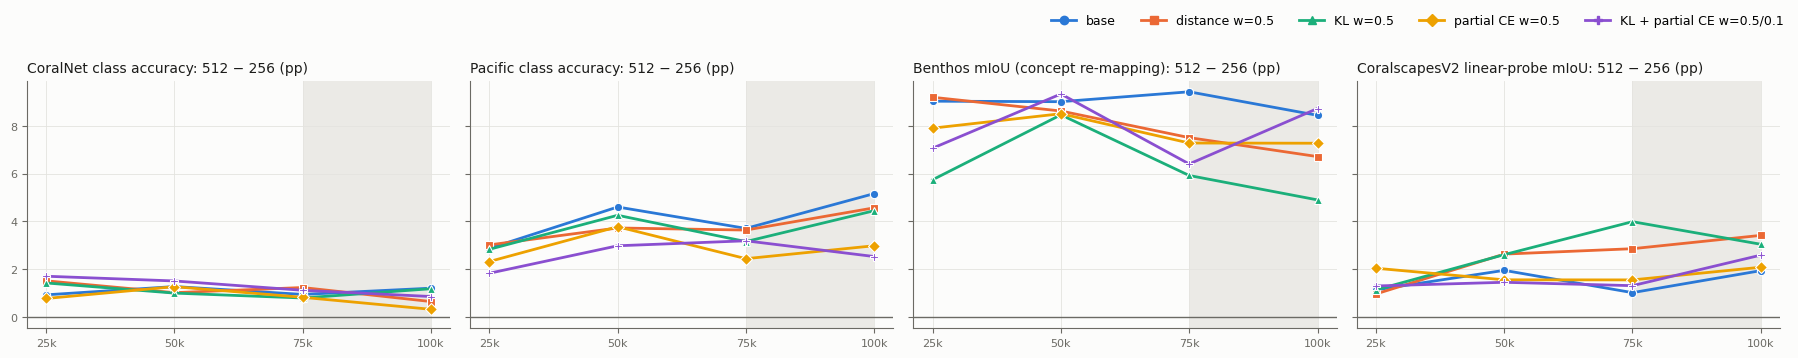

,base,distance w=0.5,KL w=0.5,partial CE w=0.5,KL + partial CE w=0.5/0.1
CoralNet class acc,+1.1,+1.1,+1.1,+0.8,+1.3
CoralNet class mIoU,+0.6,+0.7,+0.7,+0.7,+0.8
CoralNet phylum acc (living),-0.0,+0.1,+0.2,+0.7,-0.2
CoralNet family acc (living),+1.8,+1.8,+1.5,+2.4,+1.7
CoralNet genus acc (living),+1.9,+1.8,+1.4,+2.7,+1.9
CoralNet multi-hot concept F1,+3.8,+3.9,+3.8,+4.0,+4.2
CoralNet consistency (overall),+0.2,+0.2,+0.2,+0.1,+0.4
CoralNet mistake severity ↓,-2.3,-2.4,-1.8,-1.9,-2.1
CoralNet ECE ↓,+0.3,+0.3,+0.6,+0.2,+0.8
Pacific class acc,+4.1,+3.7,+3.7,+2.9,+2.6


In [4]:
def res_gain(run, col):
    a, b = df.loc[run, col], lo.loc[run, col]
    common = [s for s in a.index if s in b.index]
    return a.loc[common] - b.loc[common]


fig, axes = plt.subplots(1, len(HEADLINE), figsize=(18, 3.6), sharey=True)
for ax, (col, name) in zip(axes, HEADLINE):
    ax.axhline(0, color=MUTED, lw=1)
    for run in RUNS:
        d = res_gain(run, col) * 100
        plot_run(ax, run, d.index, d.values)
    ax.set_title(f"{name}: 512 − 256 (pp)")
    step_axis(ax, STEPS)
run_legend(fig, RUNS)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

GAIN_ROWS = [  # (column, label)
    *[(f"{ev}/{s}", f"{EVALS[ev].split(' ')[0]} {l}") for ev in EVALS for s, l in (
        ("class_accuracy", "class acc"), ("class_miou", "class mIoU"),
        *[(f"tax_{r}_acc_living", f"{r} acc (living)") for r in ("phylum", "family", "genus")],
        ("binary_macro_f1", "multi-hot concept F1"), ("consistency/overall", "consistency (overall)"),
        ("severity/mean_normalized", "mistake severity ↓"), ("ece/mean", "ECE ↓"))],
    ("benthos/miou", "Benthos mIoU"), ("coralscapes/miou", "CoralscapesV2 mIoU"),
]
gain = pd.DataFrame({style(r)[0]: [100 * res_gain(r, c).mean() for c, _ in GAIN_ROWS] for r in RUNS},
                    index=[l for _, l in GAIN_ROWS])
(gain.style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-8, vmax=8, axis=None)
 .set_caption("512 − 256 px, mean over 25k–100k, pp; ↓ rows: negative is better"))

**Reading.**
- **Gains from 512 px, mean over steps**: CoralNet class accuracy +0.8 to +1.3 pp, Pacific class accuracy +2.6 to +4.1 pp,
  Benthos +6.3 to +9.0 pp, CoralscapesV2 +1.5 to +2.7 pp, CoralNet multi-hot concept F1 +3.8 to +4.2 pp. Mistake severity
  falls by 1.5–2.4 pp for every run on both datasets. Phylum accuracy and ECE barely move (within ±1 pp, except Pacific
  phylum −0.7 to −1.7 pp).
- **Base gains the most where the loss runs had their advantage at 256 px.** On Pacific, base gains +4.1 pp class accuracy
  (vs +2.6 to +3.7), +3.2 pp family (vs +0.4 to +1.8) and +4.9 pp genus (vs +3.3 to +3.9). On Pacific class accuracy the
  gap is largest late in training: base gains +6.6 / +5.8 pp at 75k / 100k, the loss runs +2.4 to +4.6.
- Benthos also gains most for base (+9.0 pp) and least for KL w=0.5 (+6.3 pp).
- **CoralscapesV2 is the exception**: base gains the least (+1.5 pp), KL and distance the most (+2.7 / +2.5 pp).

## 3. Scorecard: each run vs base, 512 px vs 256 px
`run − base [taxv2]` in percentage points, averaged over the steps both have; whiskers are min / max over steps. Filled
markers and solid whiskers: 512 px. Hollow markers and dashed whiskers: 256 px (the scorecard of the previous notebook,
restricted to these runs). Rows are oriented so **right = better**.

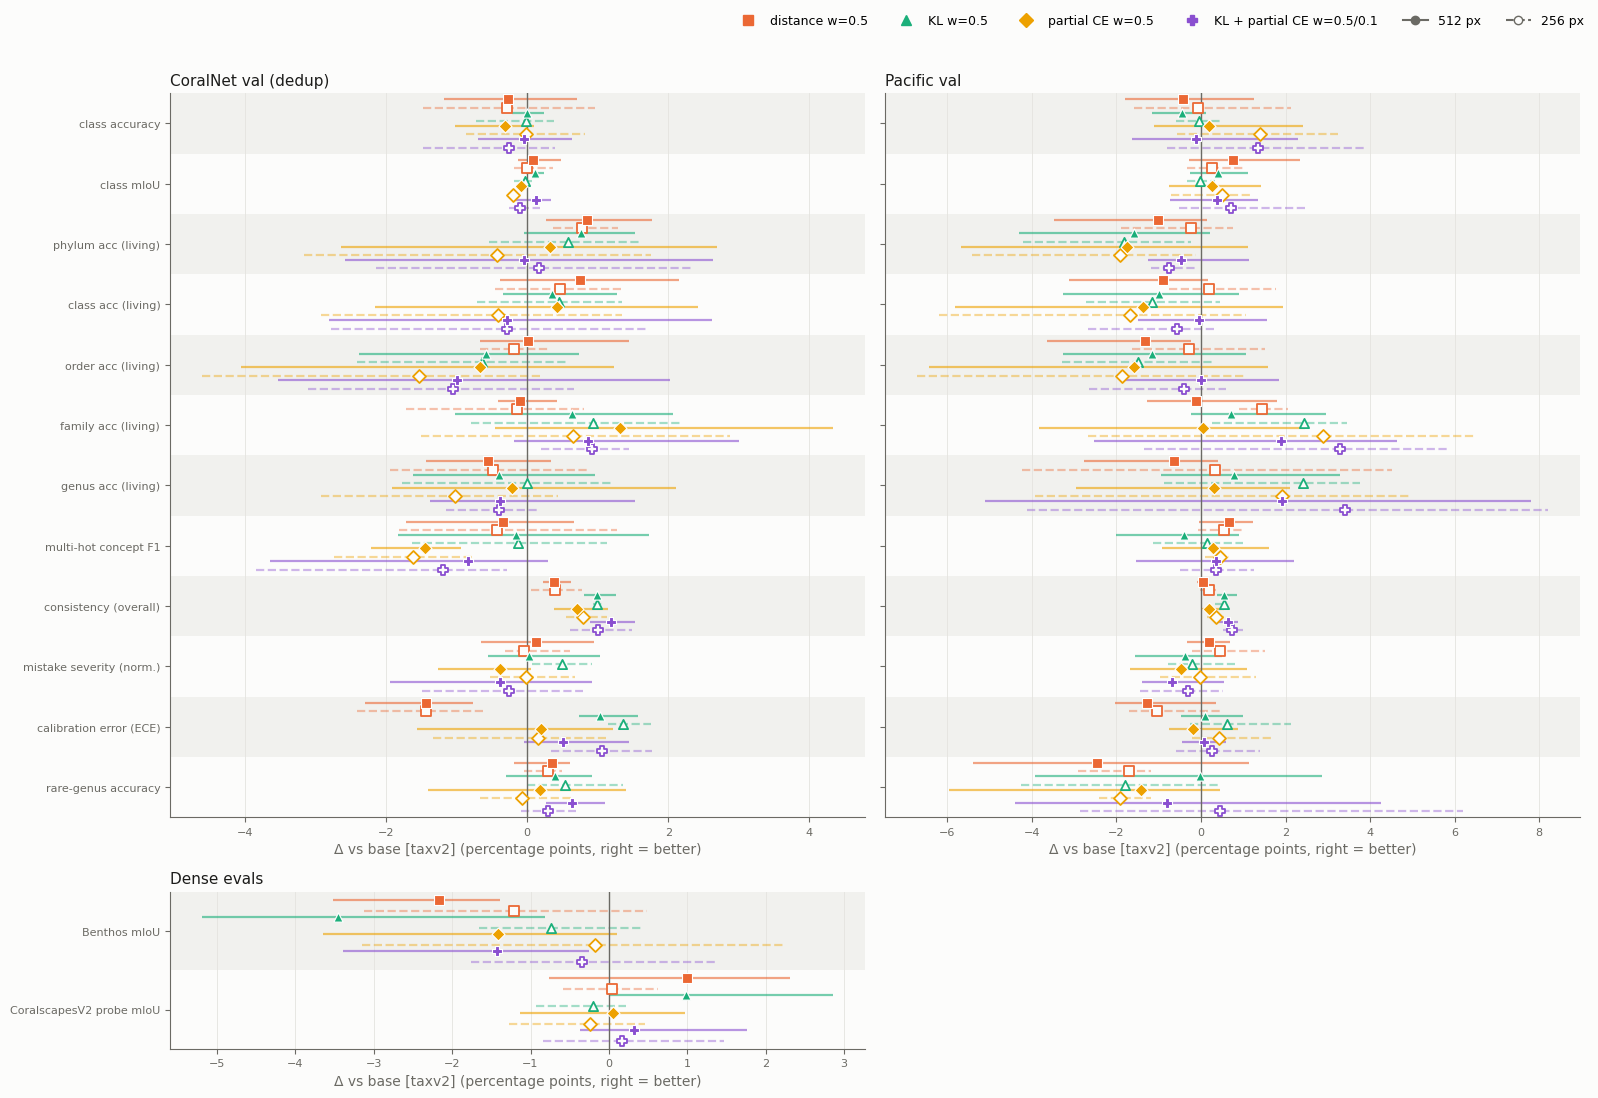

In [5]:
SCORECARD = [  # (column suffix, label, higher_is_better)
    ("class_accuracy", "class accuracy", True),
    ("class_miou", "class mIoU", True),
    *[(f"tax_{r}_acc_living", f"{r} acc (living)", True) for r in RANKS[1:]],
    ("binary_macro_f1", "multi-hot concept F1", True),
    ("consistency/overall", "consistency (overall)", True),
    ("severity/mean_normalized", "mistake severity (norm.)", False),
    ("ece/mean", "calibration error (ECE)", False),
    ("rare/genus/tail_macro_acc", "rare-genus accuracy", True),
]
OFFSETS = dict(zip(COMPARE, np.linspace(-0.33, 0.33, len(COMPARE))))


def scorecard(cols, runs=COMPARE, table=None):
    rows = []
    for col, label, hib in cols:
        for run in runs:
            d = (1 if hib else -1) * delta(run, col, table=table) * 100
            rows.append(dict(metric=label, run=run, mean=d.mean(), lo=d.min(), hi=d.max(), n=len(d)))
    return pd.DataFrame(rows)


def draw_scorecard(ax, cols, labels, title):
    y = {lab: i for i, lab in enumerate(labels)}
    for i in range(0, len(labels), 2):
        ax.axhspan(i - 0.5, i + 0.5, color=BAND, lw=0, zorder=0, alpha=0.6)
    for table, res, nudge in ((lo, LOW, 0.07), (df, RES, -0.07)):
        sc = scorecard(cols, table=table)
        for run, off in OFFSETS.items():
            _, color, marker, _ = style(run)
            s = sc[sc.run == run]
            yy = np.array([y[m] for m in s.metric]) + off + nudge
            ax.hlines(yy, s.lo, s.hi, color=color, lw=1.6, alpha=0.6 if res == RES else 0.4,
                      linestyles="-" if res == RES else "--")
            ax.scatter(s["mean"], yy, marker=marker, s=44, zorder=3,
                       color=color if res == RES else SURFACE, edgecolor="white" if res == RES else color,
                       linewidth=0.8 if res == RES else 1.3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Δ vs base [taxv2] (percentage points, right = better)")
    ax.set_title(title, fontsize=11)


fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[len(SCORECARD), 2.6])
labels = [lab for _, lab, _ in SCORECARD]
for i, ev in enumerate(EVALS):
    ax = fig.add_subplot(gs[0, i])
    draw_scorecard(ax, [(f"{ev}/{c}", l, h) for c, l, h in SCORECARD], labels, EVALS[ev])
    if i:
        ax.set_yticklabels([])
DENSE = [("benthos/miou", "Benthos mIoU", True), ("coralscapes/miou", "CoralscapesV2 probe mIoU", True)]
draw_scorecard(fig.add_subplot(gs[1, 0]), DENSE, [l for _, l, _ in DENSE], "Dense evals")
handles = [Line2D([], [], color=style(r)[1], marker=style(r)[2], ls="", ms=7, label=style(r)[0]) for r in COMPARE]
handles += [Line2D([], [], color=MUTED, marker="o", ls="-", label="512 px"),
            Line2D([], [], color=MUTED, marker="o", mfc=SURFACE, ls="--", label="256 px")]
fig.legend(handles=handles, loc="upper right", ncol=len(handles), bbox_to_anchor=(1, 1.0), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

ALLCOLS = [(f"{ev}/{c}", f"{EVALS[ev].split(' ')[0]} {l}", h) for ev in EVALS for c, l, h in SCORECARD] + DENSE
tabs = {}
for table, res in ((lo, LOW), (df, RES)):
    sc = scorecard(ALLCOLS, table=table)
    sc["run"] = sc.run.map(lambda r: style(r)[0])
    tabs[res] = sc.pivot(index="metric", columns="run", values="mean").loc[sc.metric.unique(), [style(r)[0] for r in COMPARE]]
both = pd.concat(tabs, axis=1, names=["res", "run"]).swaplevel(0, 1, axis=1)[[(style(r)[0], res) for r in COMPARE for res in (LOW, RES)]]
(both.style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-4, vmax=4, axis=None)
 .set_caption("mean Δ vs base [taxv2] over 25k–100k, pp, right = better (sign-flipped for ECE / severity)"))

**Reading** (512 px vs the 256 px values from the previous notebook; a row counts as stable only if all four checkpoints
are on the same side of 0).
- **What holds at 512 px**:
  - Consistency: still better than base at every step for KL w=0.5 (CoralNet +1.0, Pacific +0.5 pp), KL + partial CE
    (+1.2 / +0.6), partial CE w=0.5 (CoralNet +0.7) and distance w=0.5 (CoralNet +0.4).
  - Calibration: KL w=0.5 still has 1.0 pp lower CoralNet ECE than base at every step (1.4 pp at 256 px). Distance w=0.5
    is still 1.4 pp worse.
  - Partial CE w=0.5 still costs CoralNet multi-hot concept F1 (−1.4 pp, every step).
- **What shrinks or disappears**:
  - Pacific family and genus. At 256 px all w=0.5 runs were +1.4 to +3.3 pp above base on family. At 512 px it is +1.9
    (KL + partial CE), +0.7 (KL), 0.0 (partial CE) and −0.1 (distance), and none is stable.
  - Pacific class accuracy. Partial CE and the combined run were +1.4 / +1.3 pp at 256 px; at 512 px they are within
    ±0.5 pp of base.
  - CoralNet: every class-accuracy difference is within ±0.3 pp.
  - Pacific phylum / class / order accuracy is now below base for KL, partial CE and distance (−0.9 to −1.8 pp). This
    comes from 25k–50k; at 75k–100k they are within about 1 pp of base or above it.
- **Benthos is a stable cost at 512 px**: distance −2.2 pp, KL −3.5 pp and KL + partial CE −1.4 pp at every step; partial
  CE −1.4 pp on average. At 256 px no Benthos difference had a stable sign.
- **CoralscapesV2 flips**: at 512 px distance and KL are +1.0 pp above base on average (they were +0.0 / −0.2 at 256 px),
  but the sign isn't stable.

## 4. Each loss's own objective at 512 px
Absolute values on CoralNet, averaged over ranks / rank pairs; 256 px values of the same checkpoint in the last column
group for comparison.

In [6]:
OBJ = {
    "expected tree distance ↓ (mean over ranks)": [f"coralnet/expected_distance/{r}" for r in RANKS],
    "inter-head KL ↓ (mean over pairs)": [f"coralnet/kl/{p}" for p in PAIRS],
    "partial-label subtree mass ↑ (mean over pairs)": [f"coralnet/partial/{p}/subtree_mass" for p in PAIRS],
}
obj = pd.DataFrame({
    **{(name, f"{s // 1000}k"): df[cols].mean(axis=1).xs(s, level="step") for name, cols in OBJ.items() for s in STEPS},
    **{(name, "100k @256"): lo[cols].mean(axis=1).xs(100000, level="step") for name, cols in OBJ.items()},
}).reindex(RUNS)
obj = obj[[c for name in OBJ for c in obj.columns if c[0] == name]]
obj.index = [style(r)[0] for r in obj.index]
obj.style.format("{:.3f}", na_rep="—").set_caption("CoralNet val, 512 px (last column of each group: 256 px at 100k)")

**Reading.**
- **Each loss still moves its own objective, by about the same amount as at 256 px.**
  - KL w=0.5 holds the inter-head KL at 0.013–0.014 nats at every step; base is at 0.077 at 100k (about 6×). The combined
    run is the same (0.012), partial CE w=0.5 halfway (0.039).
  - Subtree mass: KL w=0.5 0.308, KL + partial CE 0.306 and partial CE 0.294, vs base 0.235. KL is still slightly ahead
    of partial CE on partial CE's own objective.
  - Distance w=0.5 is below base on expected tree distance at every step (0.202 vs 0.212 at 100k).
- 512 px lowers expected tree distance by about 0.02 for every run and changes KL and subtree mass little. The objectives
  measure the shape of the predicted distribution, which the loss sets and the input resolution mostly doesn't.

## 5. Per-rank differences vs base at 512 px
`run − base [taxv2]` at each checkpoint, in raw units, both evaluated at 512 px. Rows: per-rank accuracy on living points,
lineage consistency per rank pair, normalised mistake severity, and the three loss objectives.

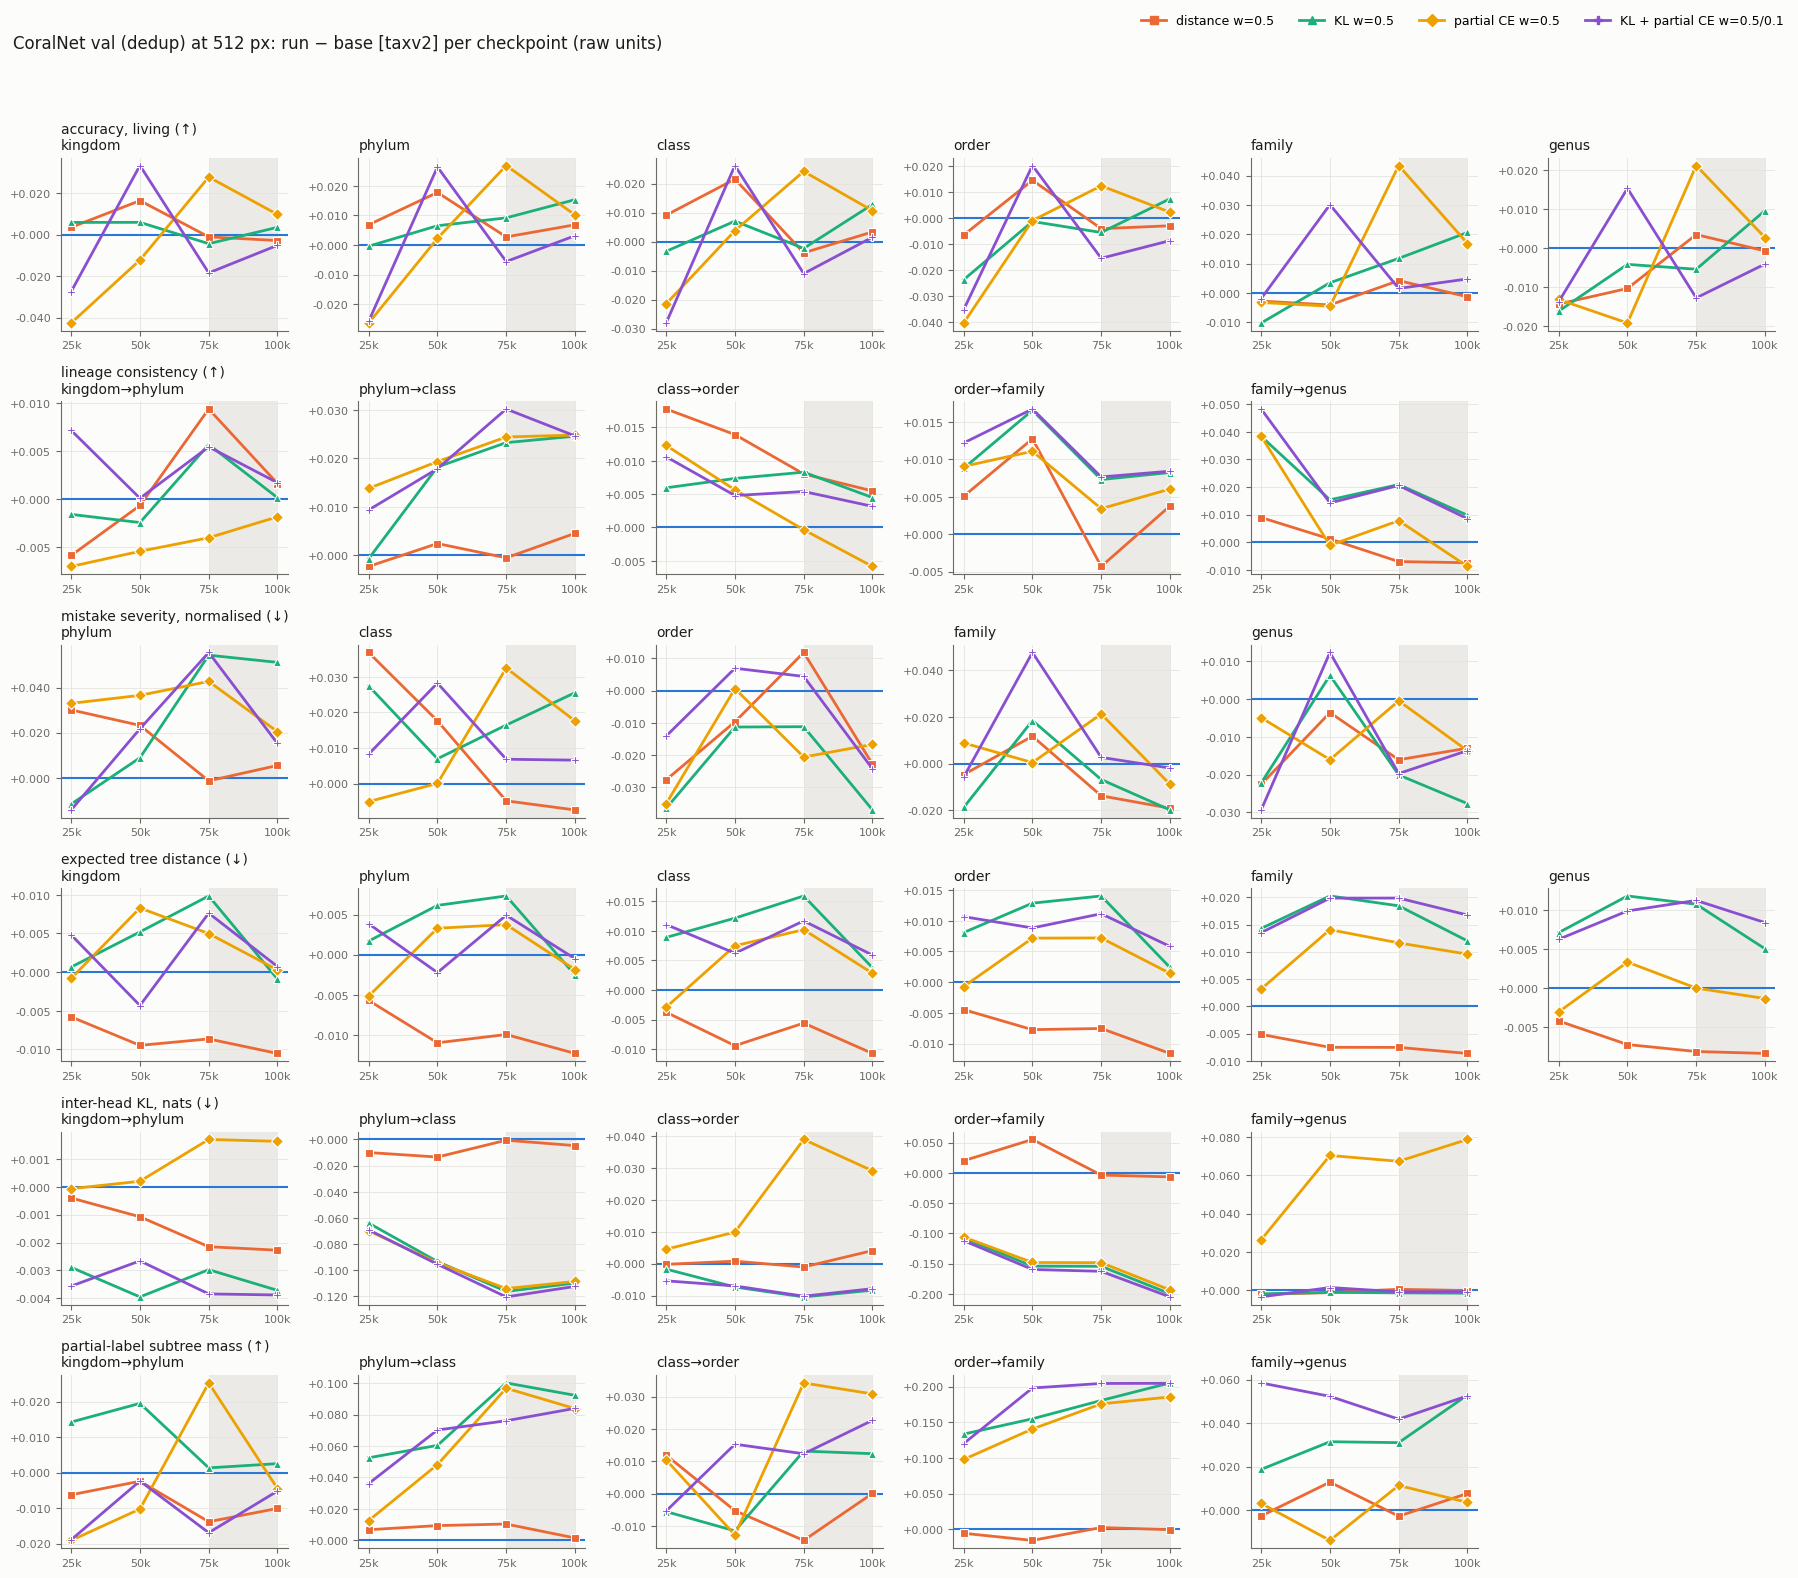

In [7]:
DELTA_ROWS = [  # (title, [(suffix, panel label)])
    ("accuracy, living (↑)", [(f"tax_{r}_acc_living", r) for r in RANKS]),
    ("lineage consistency (↑)", [(f"consistency/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("mistake severity, normalised (↓)", [(f"severity/{r}/normalized", r) for r in RANKS[1:]]),
    ("expected tree distance (↓)", [(f"expected_distance/{r}", r) for r in RANKS]),
    ("inter-head KL, nats (↓)", [(f"kl/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("partial-label subtree mass (↑)", [(f"partial/{p}/subtree_mass", p.replace("->", "→")) for p in PAIRS]),
]


def plot_deltas(ev):
    fig, axes = plt.subplots(len(DELTA_ROWS), 6, figsize=(18, 2.5 * len(DELTA_ROWS) + 0.8))
    for row_axes, (row_title, panels) in zip(axes, DELTA_ROWS):
        for i, ax in enumerate(row_axes):
            if i >= len(panels):
                ax.axis("off")
                continue
            suffix, label = panels[i]
            col = f"{ev}/{suffix}"
            ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
            for run in COMPARE:
                d = delta(run, col)
                plot_run(ax, run, d.index, d.values)
            ax.set_title(label if i else f"{row_title}\n{label}")
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
            step_axis(ax, STEPS)
    run_legend(fig, COMPARE)
    fig.suptitle(f"{EVALS[ev]} at 512 px: run − base [taxv2] per checkpoint (raw units)", x=0.01, ha="left",
                 fontsize=12, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.955))
    plt.show()


plot_deltas("coralnet")

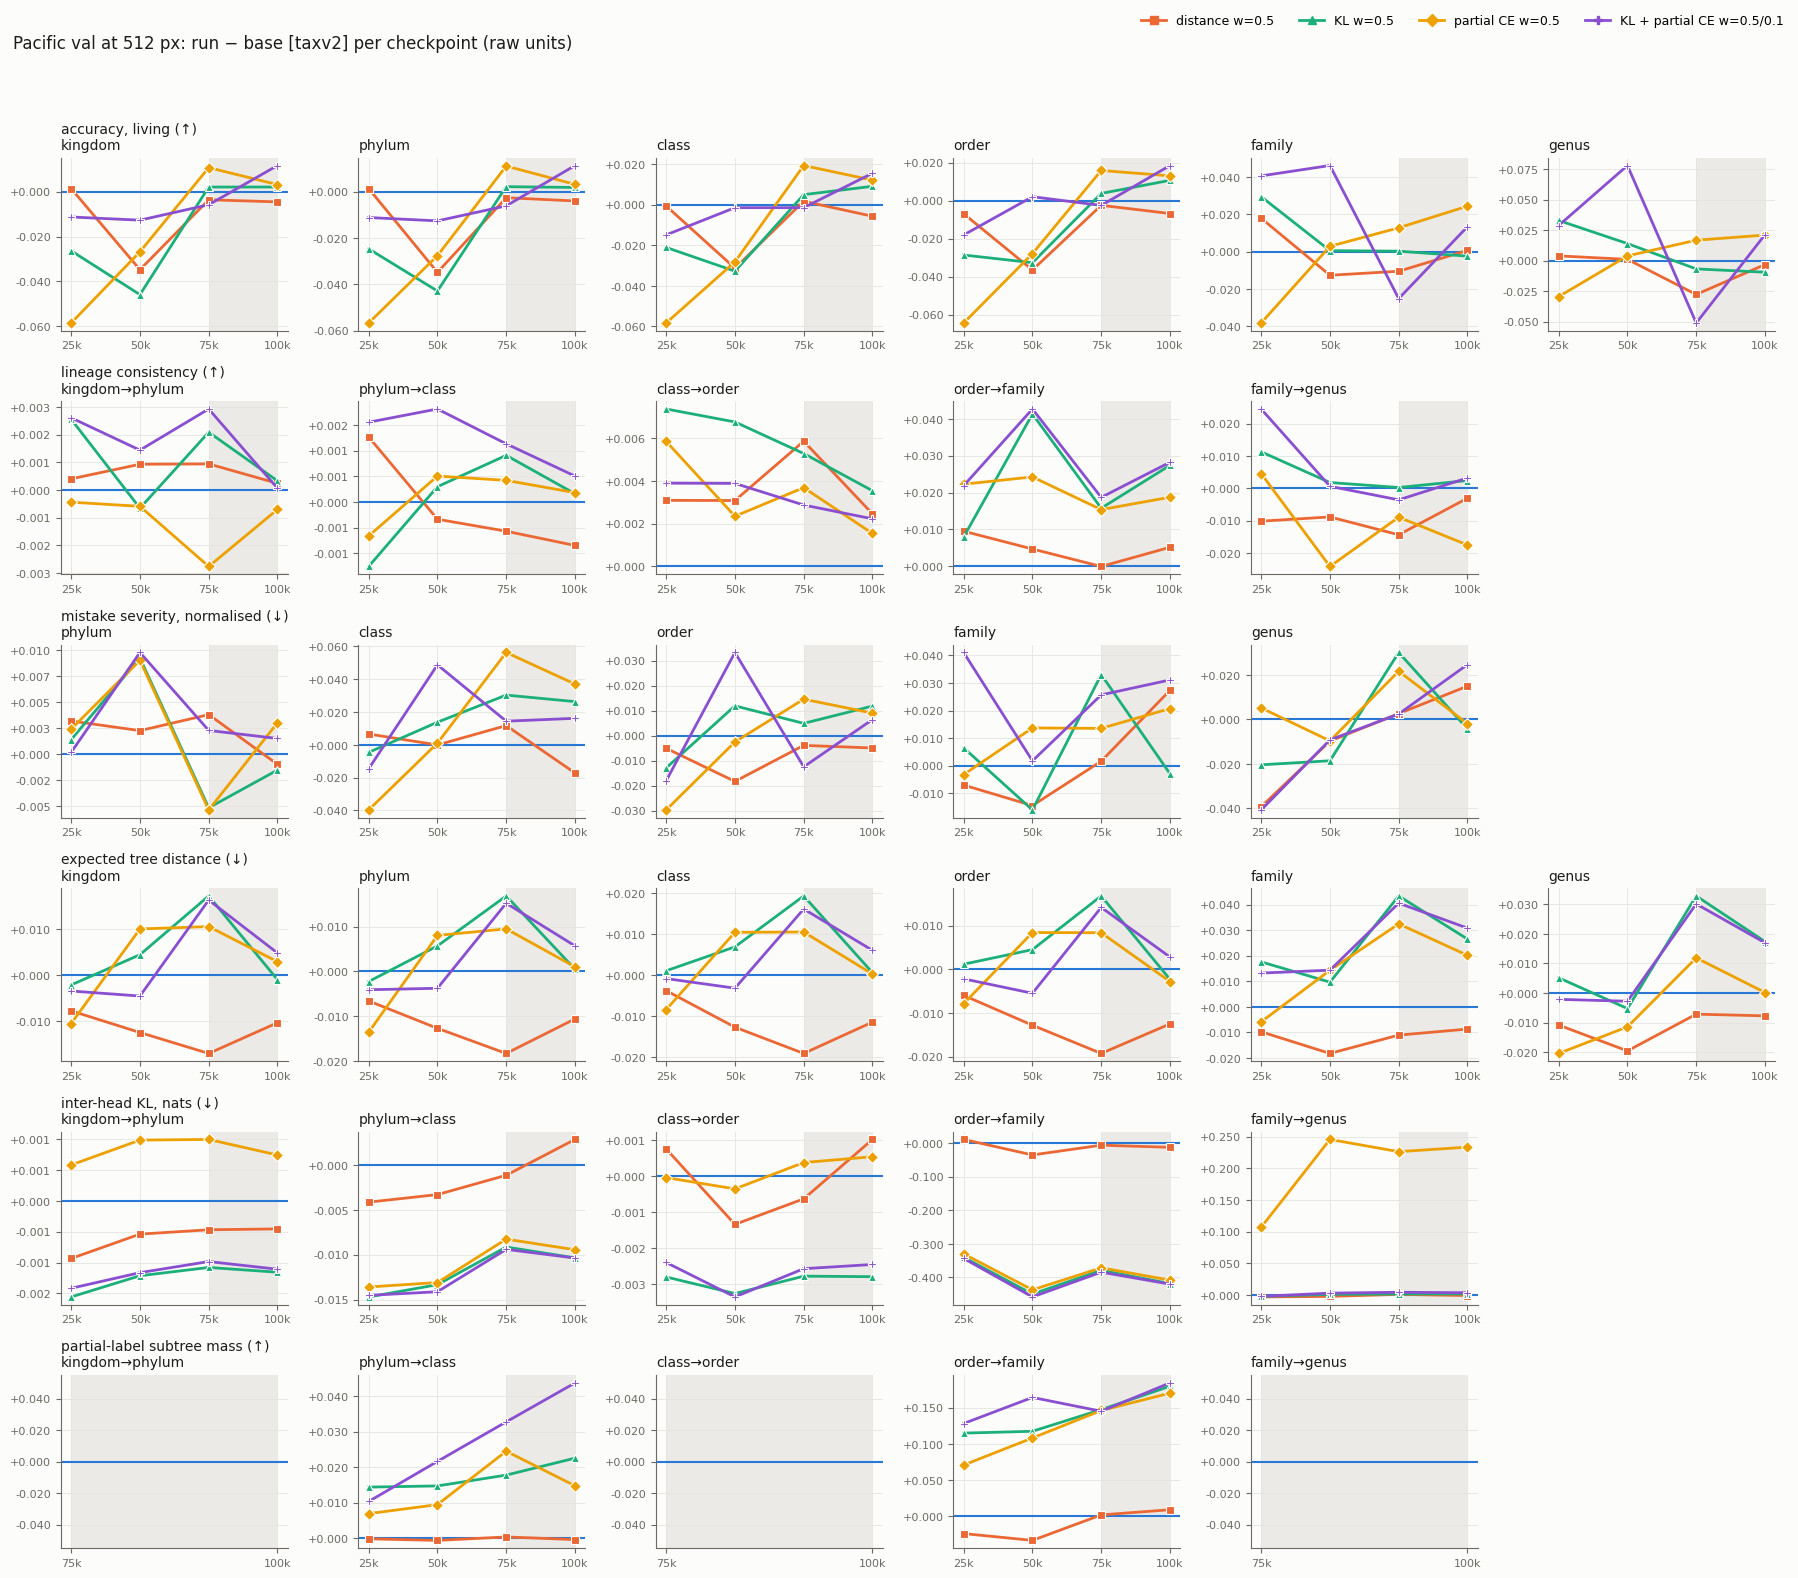

In [8]:
plot_deltas("pacific")

**Reading.**
- **Partial CE's family→genus disagreement is unchanged at 512 px**: +0.079 nats above base on CoralNet and +0.233 on
  Pacific at 100k, at every step. KL w=0.5 and the combined run stay within 0.004 of base at that pair.
- **Consistency**: on CoralNet, KL w=0.5, partial CE w=0.5 and the combined run are above base at phylum→class (+0.018 to
  +0.030 from 50k) and order→family at every step. At family→genus only KL w=0.5 and the combined run are above base at
  every step (+0.009 to +0.048). On Pacific the gain is at order→family (KL +0.008 to +0.041, combined +0.019 to +0.043).
  Partial CE and distance are below base at Pacific family→genus at three or four steps.
- **Pacific rank accuracy**: at 25k–50k the loss runs are up to 6 pp below base from kingdom to order, as at 256 px. At
  75k–100k they are within about 2 pp. The family and genus gains seen at 256 px are no longer consistent: at 100k partial
  CE is +2.4 / +2.1 pp, the combined run +1.3 / +2.1 pp, and KL and distance are within 1 pp of base.
- **Mistake severity**: KL w=0.5 makes less severe order-level mistakes on CoralNet at every step (−0.011 to −0.037), as
  at 256 px, but more severe phylum- and class-level ones from 75k (+0.016 to +0.054). Severity is lower at genus level
  for distance at every step (−0.004 to −0.023).

## 6. Calibration and rare taxa at 512 px
Top two rows: `run − base [taxv2]` at 512 px for the mean ECE over ranks, and macro accuracy over head (common) and tail
(rare) taxa at family and genus. Bottom row: absolute ECE at both resolutions.

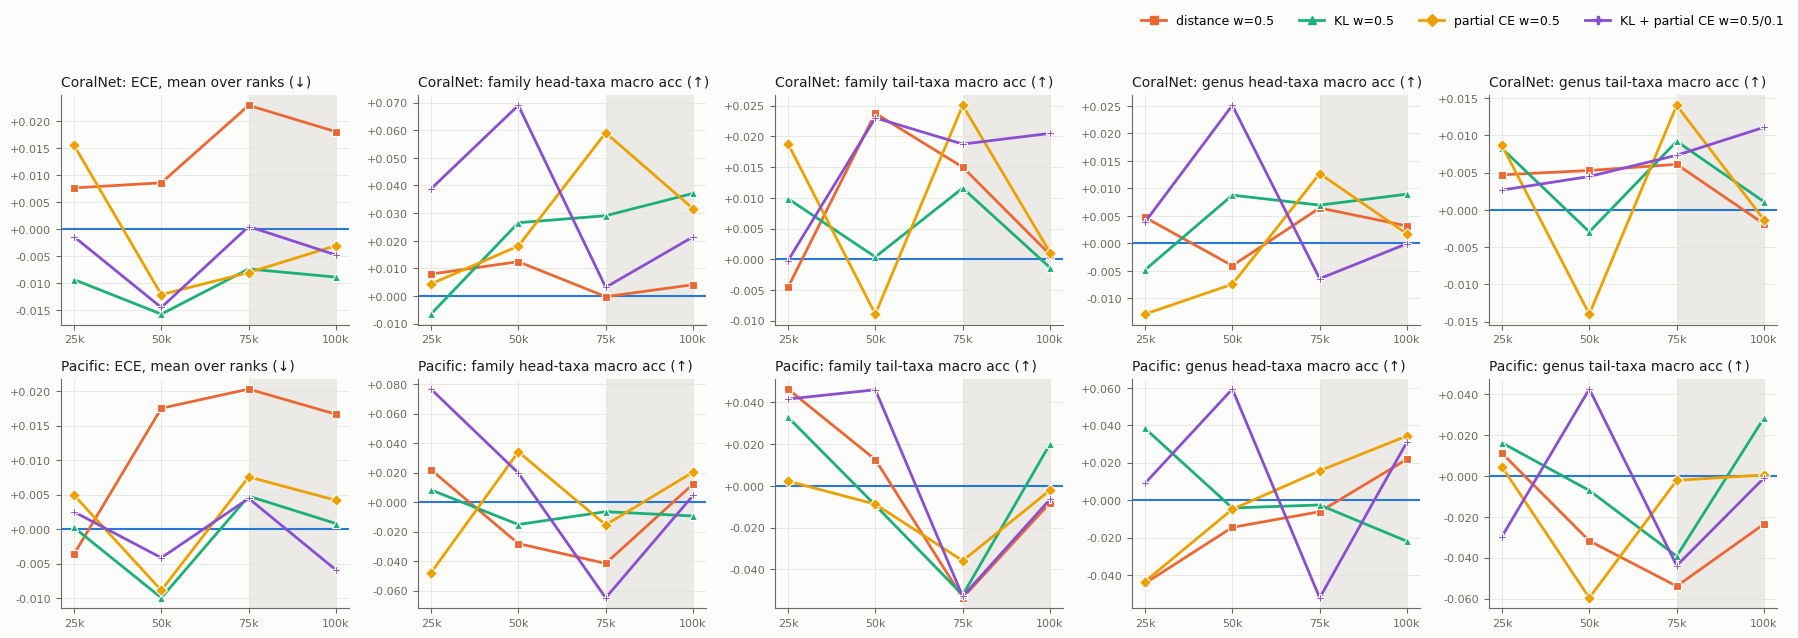

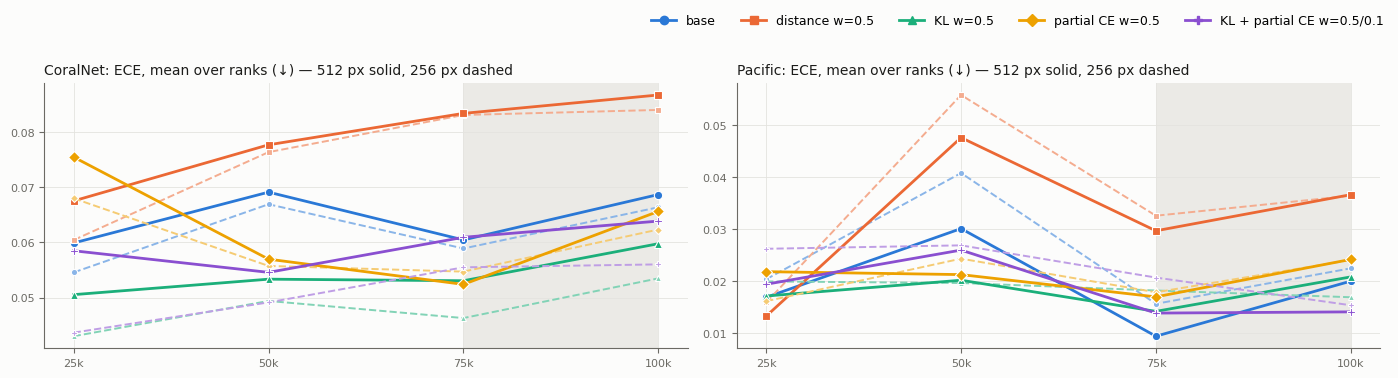

In [9]:
CALIB = [("ece/mean", "ECE, mean over ranks (↓)")] + [
    (f"rare/{r}/{s}_macro_acc", f"{r} {s}-taxa macro acc (↑)") for r in ("family", "genus") for s in ("head", "tail")]
fig, axes = plt.subplots(2, len(CALIB), figsize=(18, 6.4))
for row, ev in zip(axes, EVALS):
    for ax, (suffix, title) in zip(row, CALIB):
        ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
        for run in COMPARE:
            d = delta(run, f"{ev}/{suffix}")
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{EVALS[ev].split(' ')[0]}: {title}")
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
        step_axis(ax, STEPS)
run_legend(fig, COMPARE)
fig.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, ev in zip(axes, EVALS):
    for run in RUNS:
        plot_run(ax, run, lo.loc[run, f"{ev}/ece/mean"].index, lo.loc[run, f"{ev}/ece/mean"].values, res=LOW)
        plot_run(ax, run, df.loc[run, f"{ev}/ece/mean"].index, df.loc[run, f"{ev}/ece/mean"].values)
    ax.set_title(f"{EVALS[ev].split(' ')[0]}: ECE, mean over ranks (↓) — 512 px solid, 256 px dashed")
    step_axis(ax, STEPS)
run_legend(fig, RUNS)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

**Reading.**
- **CoralNet ECE**: KL w=0.5 is below base at every step (0.051–0.060 vs 0.060–0.069). Distance w=0.5 is the worst and gets
  worse with training (0.068 → 0.087). Partial CE and the combined run are within 1.5 pp of base after 25k.
- **Pacific ECE**: base varies from 0.009 to 0.030 between steps. KL and the combined run are within 1 pp of it, and
  distance is above it from 50k (+1.7 to +2.0 pp).
- Compared with 256 px, ECE changes by less than 1 pp per run. The calibration ranking (KL best, distance worst) is the
  same at both resolutions.
- **CoralNet family head taxa**: KL w=0.5 (+2.7 to +3.7 pp from 50k) and partial CE w=0.5 (+0.4 to +5.9 pp, every step)
  are above base. Genus head and tail differences on CoralNet are within ±2.5 pp.
- **Pacific rare taxa**: every run moves between −6 and +8 pp from step to step, with no stable sign. Distance w=0.5 is
  below base on tail genus at 50k–100k (−2.3 to −5.4 pp).

## 7. Summary

1. **512 px is a free improvement for every run**: +0.8 to +1.3 pp CoralNet class accuracy, +2.6 to +4.1 pp Pacific, +6 to
   +9 pp Benthos and +1.5 to +2.7 pp CoralscapesV2, with less severe mistakes. Training resolution is unchanged, so this
   comes only from evaluating at higher resolution.
2. **Base gains the most, and the w=0.5 runs no longer improve classification accuracy.** At 512 px, CoralNet class
   accuracy is within ±0.4 pp of base for every run. Base has the highest Pacific class accuracy at 75k–100k, and the
   Pacific family / genus gains seen at 256 px shrink to ≤ 2 pp with no stable sign. Part of what the auxiliary losses
   gave at 256 px seems to be what base gets from more resolution.
3. **The hierarchical effects hold.** At 512 px KL w=0.5 keeps the inter-head KL at a sixth of base's, has higher lineage
   consistency (+1.0 pp CoralNet, +0.5 pp Pacific) and lower CoralNet ECE (−1.0 pp), all at every step. Partial CE's
   family→genus disagreement and its cost on multi-hot F1 also hold, as do distance w=0.5's lower expected tree distance and
   worse calibration.
4. **Benthos becomes a stable cost.** Every w=0.5 run is below base at 512 px on average (−1.4 to −3.5 pp). For distance,
   KL and the combined run this holds at every step; KL w=0.5 is worst. At 256 px the same differences changed sign between
   steps.
5. **Choice of loss**: if the goal is consistent, calibrated hierarchical predictions, KL w=0.5 is still the pick. Its
   benefits hold at both resolutions, and it costs Benthos mIoU (−3.5 pp at 512 px). If the goal is accuracy, nothing
   beats base at 512 px. Partial CE's 256 px accuracy lead does not hold at 512 px, and distance remains the one to drop.

One seed, and the checkpoint-to-checkpoint swings (1–2 pp on CoralNet, 2–4 pp on Pacific) are about the size of most
differences between runs here. Next steps:
- Train at 512 px to test whether base's larger gain is specific to evaluating a 256 px model at higher resolution.
- Add a second seed of base and KL w=0.5.